# Heart Disease | From Data Quality to Honest Evaluation
**An end-to-end data science study of a multi-centre clinical dataset.**

Can recorded clinical measurements distinguish patients with a positive heart disease label?
This notebook combines data auditing, focused exploratory analysis, reproducible pipelines,
model comparison, and an explicit assessment of uncertainty and site differences.

> **Scope:** educational classification of an existing diagnosis label, not future-risk forecasting or a clinical decision tool.

**Workflow:** [Data audit](#1-data-audit) · [Exploration](#3-training-set-exploration) ·
[Models](#5-training-only-model-comparison) · [Evaluation](#7-final-holdout-evaluation) · [Limitations](#10-conclusions-and-limitations)

The supplied CSV is a transformed multi-centre version of the
[UCI Heart Disease data](https://archive.ics.uci.edu/dataset/45/heart+disease).
Its exact download history is not recorded; see [DATA.md](DATA.md) for attribution, schema, and local-file fingerprint.

In [1]:
from pathlib import Path
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.model_selection import (
    LeaveOneGroupOut, StratifiedKFold, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
ROOT = Path.cwd()
DATA_PATH = ROOT / 'heart_disease_uci.csv'
REPORTS = ROOT / 'reports'
REPORTS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette=['#167d9a', '#e58054'])
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

Python 3.11.3 | pandas 2.2.3 | scikit-learn 1.6.1


## 1. Data audit
The target is **`num > 0`** (recorded disease present); `num == 0` is the negative class.
`num` must never be used as a predictor. `id` is an identifier; `dataset` is a collection-site marker.
Both are excluded from the model. Site remains available for auditing distribution shifts.

We validate the schema and target before cleaning. Exact duplicate records are removed first.
We then conservatively keep only one occurrence of an identical clinical profile **including the original target and site**, ignoring `id`.
These could be different patients; this removes two additional rows but prevents identical profiles crossing the train/test boundary.
No arbitrary missingness threshold drops patients or features.

In [2]:
raw = pd.read_csv(DATA_PATH)
NUMERIC = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
CATEGORICAL = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
FEATURES = NUMERIC + CATEGORICAL
assert set(raw.columns) == set(FEATURES + ['id', 'dataset', 'num']), 'Unexpected CSV schema'
assert raw['num'].notna().all() and raw['num'].isin(range(5)).all(), 'Invalid diagnosis label'
assert raw['id'].notna().all() and raw['dataset'].notna().all()
for column in NUMERIC:
    raw[column] = pd.to_numeric(raw[column], errors='raise')

exact_duplicates = int(raw.duplicated().sum())
data = raw.drop_duplicates().copy()
profile_duplicates = int(data.drop(columns='id').duplicated().sum())
data = data.drop_duplicates(subset=[c for c in data.columns if c != 'id']).copy()
assert data['id'].is_unique, 'Conflicting records share a patient ID'

# These two measurements cannot be zero; keep the raw CSV intact.
zero_counts = data[['trestbps', 'chol']].eq(0).sum()
data[['trestbps', 'chol']] = data[['trestbps', 'chol']].replace(0, np.nan)
# Preserve negative oldpeak values: they may encode ST elevation, not a data-entry error.
for column in CATEGORICAL:
    data[column] = data[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
data['target'] = (data['num'] > 0).astype(int)
assert data[FEATURES].notna().any().all()
assert np.isfinite(data[NUMERIC].to_numpy(dtype=float)[data[NUMERIC].notna()]).all()

print(f'CSV SHA-256: {hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()}')
print(f'Raw: {raw.shape} | Exact duplicates: {exact_duplicates} | Additional repeated profiles: {profile_duplicates}')
print(f'Analysis: {data.shape[0]} records | Zero BP: {zero_counts.trestbps} | Zero cholesterol: {zero_counts.chol}')
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'raw_missing': raw.isna().sum(),
                      'analysis_missing': data[raw.columns].isna().sum()}))

CSV SHA-256: acc0c823fe8a105fffda476b2d3e5e45f0642ca75afd8285879384a7d6d130f8
Raw: (922, 16) | Exact duplicates: 2 | Additional repeated profiles: 2
Analysis: 918 records | Zero BP: 1 | Zero cholesterol: 172


,dtype,raw_missing,analysis_missing
id,int64,0,0
age,int64,0,0
sex,object,0,0
dataset,object,0,0
cp,object,0,0
trestbps,float64,60,60
chol,float64,30,201
fbs,object,90,90
restecg,object,2,2
thalch,float64,56,55


## 2. Split before exploration or learning
Reserve a stratified **20% holdout**, seed 42, before studying relationships or fitting any transformations.
All exploratory plots, feature summaries, PCA, cross-validation, and site stress tests below use training rows only.
The holdout is opened once after selecting a model by mean training CV ROC-AUC.

The value-based zero correction and duplicate policy above are fixed data-integrity rules, not estimated transformations.
Medians, category vocabularies, scales, and model parameters are learned within each training fold.

In [3]:
X = data[FEATURES]
y = data['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y,
)
assert set(X_train.index).isdisjoint(X_test.index)
assert not {'id', 'num', 'dataset', 'target'}.intersection(X_train.columns)
assert len(X_train) + len(X_test) == len(data)
train = data.loc[X_train.index].copy()
display(pd.DataFrame({'records': [len(X_train), len(X_test)],
                      'positive_fraction': [y_train.mean(), y_test.mean()]}, index=['Train', 'Holdout']))

,records,positive_fraction
Train,734,0.553134
Holdout,184,0.554348


## 3. Training-set exploration
Start with coverage and case mix: pooling hospitals can hide very different measurement practices and class proportions.
The observed positive fraction describes this sample, not disease prevalence in the general population.

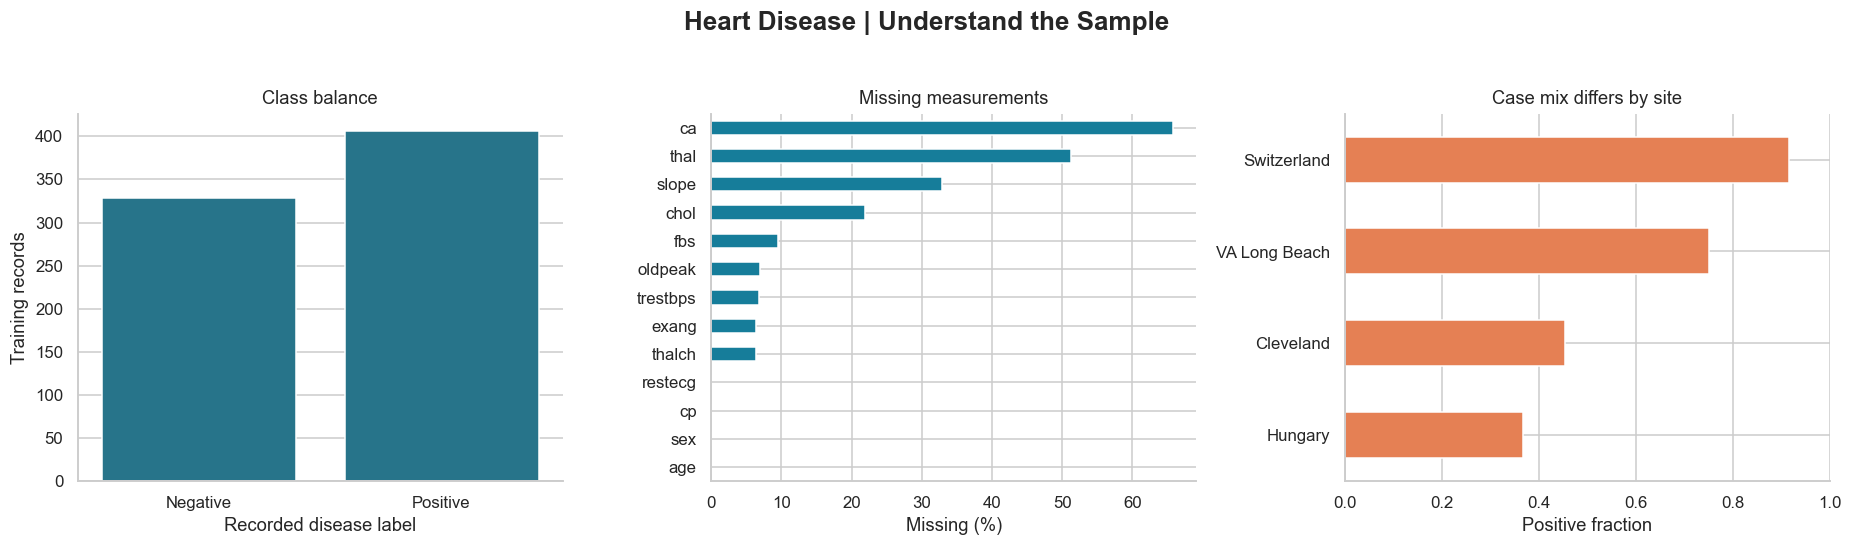

,records,positive_fraction
dataset,,
Cleveland,249,0.454
Hungary,228,0.368
Switzerland,96,0.917
VA Long Beach,161,0.752


,age,trestbps,chol,thalch,oldpeak,ca,sex,cp,fbs,restecg,exang,slope,thal
dataset,,,,,,,,,,,,,
Cleveland,0.0,0.000,0.000,0.000,0.000,0.020,0.0,0.0,0.000,0.0,0.000,0.004,0.004
Hungary,0.0,0.004,0.083,0.004,0.000,0.991,0.0,0.0,0.026,0.0,0.004,0.640,0.908
Switzerland,0.0,0.021,1.000,0.010,0.042,0.969,0.0,0.0,0.604,0.0,0.010,0.135,0.385
VA Long Beach,0.0,0.292,0.286,0.280,0.292,0.988,0.0,0.0,0.037,0.0,0.280,0.503,0.814


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.countplot(data=train, x='target', ax=axes[0], color='#167d9a')
axes[0].set_xticks([0, 1], labels=['Negative', 'Positive'])
axes[0].set(xlabel='Recorded disease label', ylabel='Training records', title='Class balance')
(train[FEATURES].isna().mean().mul(100).sort_values()
 .plot.barh(ax=axes[1], color='#167d9a'))
axes[1].set(xlabel='Missing (%)', title='Missing measurements')
site_summary = train.groupby('dataset')['target'].agg(records='size', positive_fraction='mean')
site_summary['positive_fraction'].sort_values().plot.barh(ax=axes[2], color='#e58054')
axes[2].set(xlabel='Positive fraction', ylabel='', xlim=(0, 1), title='Case mix differs by site')
fig.suptitle('Heart Disease | Understand the Sample', fontsize=17, fontweight='bold', y=1.03)
fig.tight_layout()
fig.savefig(REPORTS / 'summary.png', bbox_inches='tight')
plt.show()
display(site_summary.round(3))
display(train.groupby('dataset')[FEATURES].agg(lambda values: values.isna().mean()).round(3))

### Clinical measurements and relationships
Plot measured values before imputation. Missing observations are omitted separately for each plot.
Zero blood pressure and cholesterol have already been marked missing. Large values are retained:
being unusual does not by itself make a clinical measurement erroneous.

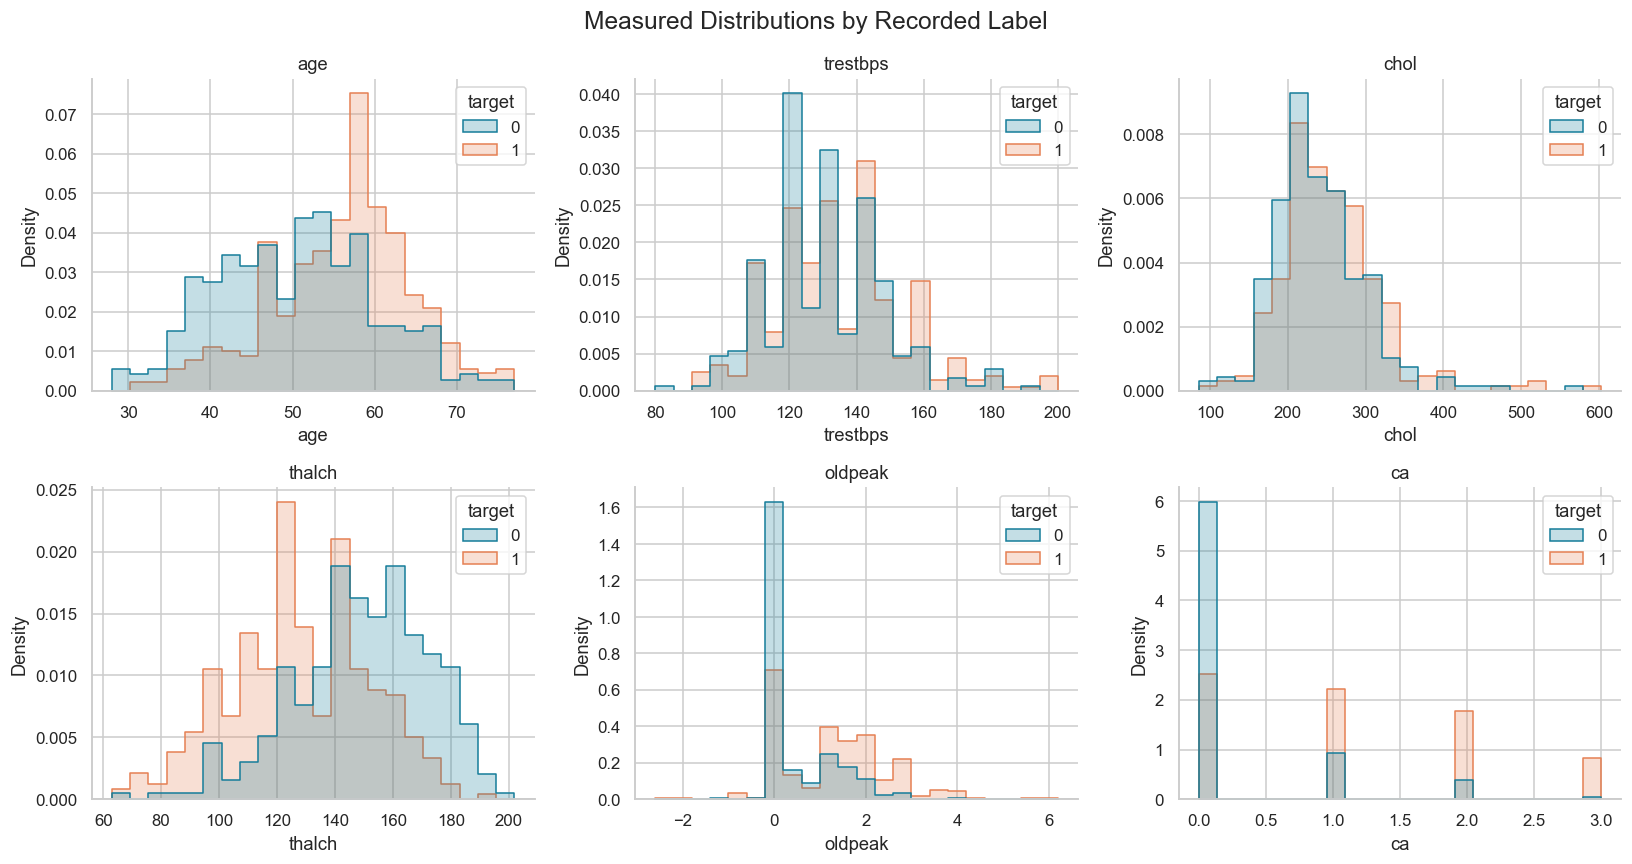

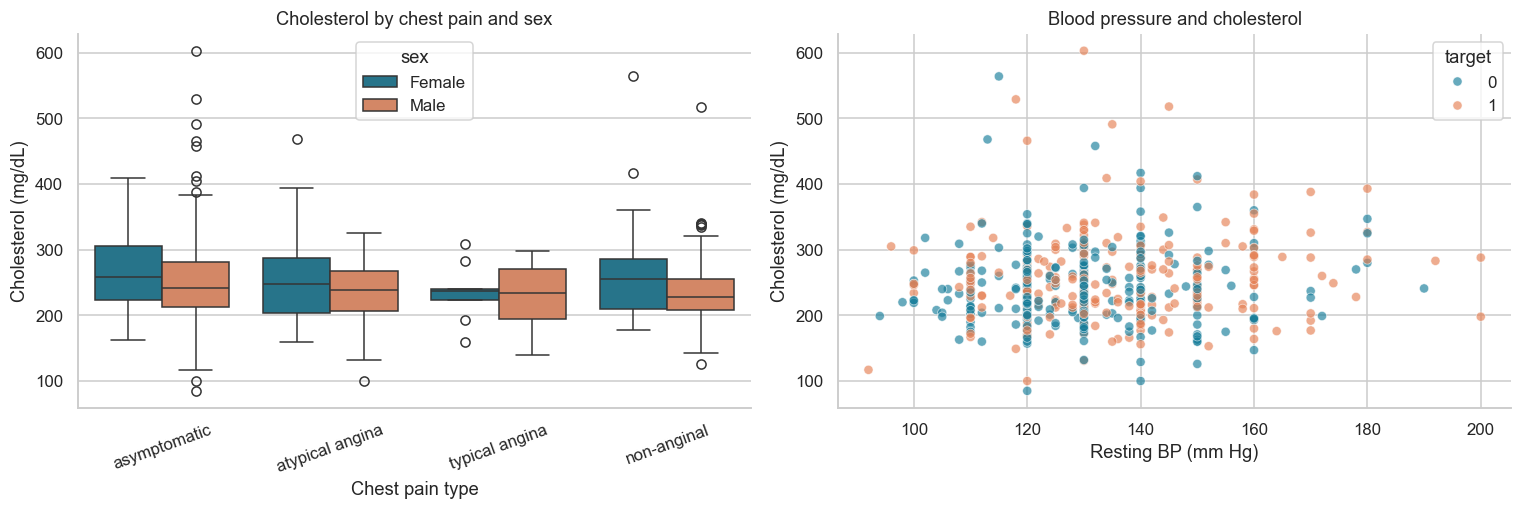

records  mean_age  median_cholesterol  mean_oldpeak
cp              sex                                                        
asymptomatic    Female       57     54.49               258.0          1.11
                Male        335     55.22               241.5          1.19
atypical angina Female       46     49.09               247.0          0.30
                Male         93     49.66               238.0          0.31
non-anginal     Female       45     52.91               255.5          0.40
                Male        123     53.04               228.5          0.75
typical angina  Female       10     54.20               237.0          0.73
                Male         25     55.56               233.5          1.25

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, ax in zip(NUMERIC, axes.flat):
    sns.histplot(data=train, x=column, hue='target', bins=22, element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(column)
fig.suptitle('Measured Distributions by Recorded Label', fontsize=16)
fig.tight_layout()
fig.savefig(REPORTS / 'distributions.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=train, x='cp', y='chol', hue='sex', ax=axes[0])
axes[0].set(title='Cholesterol by chest pain and sex', xlabel='Chest pain type', ylabel='Cholesterol (mg/dL)')
axes[0].tick_params(axis='x', rotation=20)
sns.scatterplot(data=train, x='trestbps', y='chol', hue='target', alpha=0.65, ax=axes[1])
axes[1].set(title='Blood pressure and cholesterol', xlabel='Resting BP (mm Hg)', ylabel='Cholesterol (mg/dL)')
fig.tight_layout()
plt.show()
display(train.groupby(['cp', 'sex']).agg(records=('target', 'size'),
        mean_age=('age', 'mean'), median_cholesterol=('chol', 'median'),
        mean_oldpeak=('oldpeak', 'mean')).round(2))

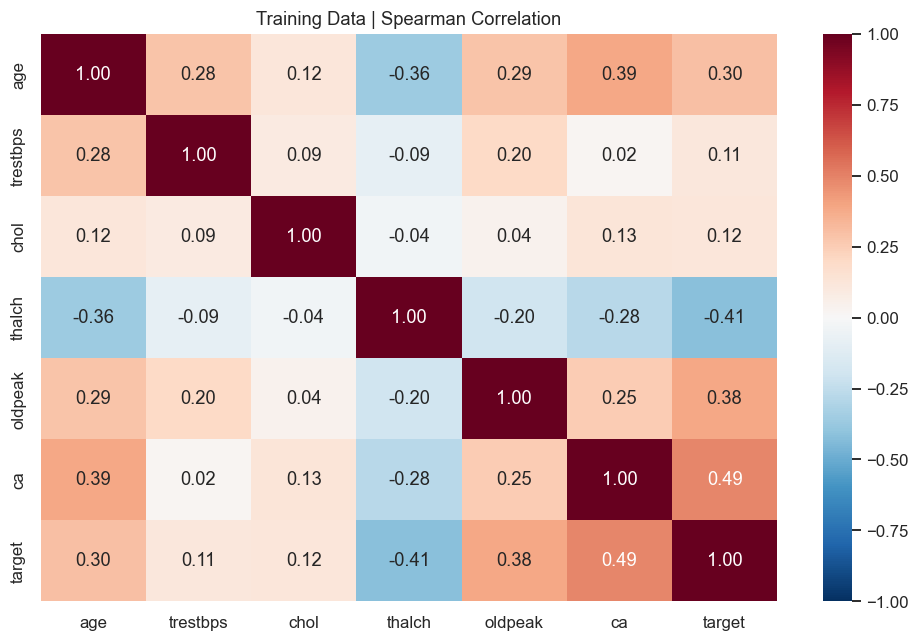

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
correlations = train[NUMERIC + ['target']].corr(method='spearman')
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Training Data | Spearman Correlation')
fig.tight_layout()
plt.show()

**Interpretation:** rank correlations are descriptive, use pairwise available observations, and do not establish causation.
Differences between Pearson and Spearman correlations alone are not a test for nonlinearity.
Missingness varies substantially across sites, especially for `ca` and `thal`.
Keep those fields with fold-specific imputation, but treat any apparent predictive benefit cautiously.

## 4. Preprocessing without leakage
Numeric features: median imputation with missingness indicators, then standard scaling.
Categorical features: an explicit `Missing` category and one-hot encoding with unknown-category handling.
No site identifiers, diagnosis grades, hand-picked correlation filters, or globally fitted clipping limits enter the predictor.

The same pipeline structure is refitted inside every CV fold. Scaling is shared across models for simplicity;
the random forest does not require it. Sparse clinical fields are retained rather than silently discarded.

In [7]:
preprocess = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
        ('scaler', StandardScaler()),
    ]), NUMERIC),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing', keep_empty_features=True)),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), CATEGORICAL),
])
models = {
    'Dummy baseline': DummyClassifier(strategy='prior'),
    'Logistic regression': LogisticRegression(max_iter=2000, solver='liblinear', random_state=SEED),
    'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features='sqrt', random_state=SEED, n_jobs=1),
}
pipelines = {name: Pipeline([('preprocess', clone(preprocess)), ('model', model)]) for name, model in models.items()}

## 5. Training-only model comparison
Use five stratified folds with a fixed seed. **Primary selection metric: mean ROC-AUC.**
Also report average precision, balanced accuracy, F1, and recall at the default 0.5 decision threshold.
The dummy baseline checks whether learned models improve on class proportions alone.

These are three predefined candidates; no hyperparameter search or test-driven threshold tuning is performed.
Fold standard deviations describe variation across folds, not a confidence interval or proof of significance.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'roc_auc': 'roc_auc', 'average_precision': 'average_precision',
           'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1', 'recall': 'recall'}
rows = []
for name, pipeline in pipelines.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
    row = {'model': name}
    for metric in scoring:
        row[f'{metric}_mean'] = scores[f'test_{metric}'].mean()
        row[f'{metric}_std'] = scores[f'test_{metric}'].std(ddof=1)
    rows.append(row)
cv_results = pd.DataFrame(rows).set_index('model').sort_values('roc_auc_mean', ascending=False)
assert np.isfinite(cv_results.to_numpy()).all()
selected_name = cv_results.index[0]
selected = clone(pipelines[selected_name]).fit(X_train, y_train)
# Verify that learned numeric preprocessing uses training rows only.
fitted_numeric = selected.named_steps['preprocess'].named_transformers_['numeric']
np.testing.assert_allclose(
    fitted_numeric.named_steps['imputer'].statistics_, X_train[NUMERIC].median().to_numpy(),
)
assert fitted_numeric.named_steps['scaler'].n_samples_seen_ == len(X_train)
cv_results.to_csv(REPORTS / 'cv_results.csv')
display(cv_results.round(3))
print('Selected by training CV:', selected_name)

,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std,recall_mean,recall_std
model,,,,,,,,,,
Logistic regression,0.888,0.053,0.898,0.058,0.815,0.070,0.841,0.052,0.855,0.026
Random forest,0.883,0.054,0.886,0.063,0.815,0.066,0.840,0.051,0.852,0.050
Dummy baseline,0.500,0.000,0.553,0.003,0.500,0.000,0.712,0.003,1.000,0.000


Selected by training CV: Logistic regression


## 6. Site transfer stress test (training partition only)
Random splits include familiar hospitals on both sides. To test a harder setting, train a predefined logistic regression
on three training-partition sites and evaluate on the remaining site's training-partition rows.

This diagnostic does not change model selection and never uses the holdout.
Per-site AUC is omitted when a validation site has only one class. Four sites are too few for broad generalisation claims.
Even without site as an input, missingness and other measurements can act as site proxies.

In [9]:
site_rows = []
groups = train['dataset']
for fit_indices, validation_indices in LeaveOneGroupOut().split(X_train, y_train, groups):
    site_model = clone(pipelines['Logistic regression']).fit(X_train.iloc[fit_indices], y_train.iloc[fit_indices])
    site_y = y_train.iloc[validation_indices]
    site_prob = site_model.predict_proba(X_train.iloc[validation_indices])[:, 1]
    site_rows.append({'site': groups.iloc[validation_indices].iloc[0], 'records': len(site_y),
                      'positive_fraction': site_y.mean(),
                      'roc_auc': roc_auc_score(site_y, site_prob) if site_y.nunique() == 2 else np.nan,
                      'accuracy': accuracy_score(site_y, site_prob >= 0.5)})
site_results = pd.DataFrame(site_rows).set_index('site')
site_results.to_csv(REPORTS / 'site_validation.csv')
display(site_results.round(3))

,records,positive_fraction,roc_auc,accuracy
site,,,,
Cleveland,249,0.454,0.816,0.703
Hungary,228,0.368,0.903,0.829
Switzerland,96,0.917,0.696,0.823
VA Long Beach,161,0.752,0.684,0.739


## 7. Final holdout evaluation
The selected pipeline is already fitted on all training rows. Evaluate the reserved holdout now, using threshold 0.5.
Recall measures the fraction of positives detected; precision measures the fraction of positive predictions that are correct.
Average precision is sensitive to class proportions. Brier score summarises squared probability error (lower is better),
but does not by itself establish calibration.

,holdout
roc_auc,0.926
average_precision,0.933
accuracy,0.864
balanced_accuracy,0.860
precision,0.860
recall,0.902
specificity,0.817
f1,0.880
brier_score,0.106


              precision    recall  f1-score   support

    Negative      0.870     0.817     0.843        82
    Positive      0.860     0.902     0.880       102

    accuracy                          0.864       184
   macro avg      0.865     0.860     0.862       184
weighted avg      0.864     0.864     0.864       184



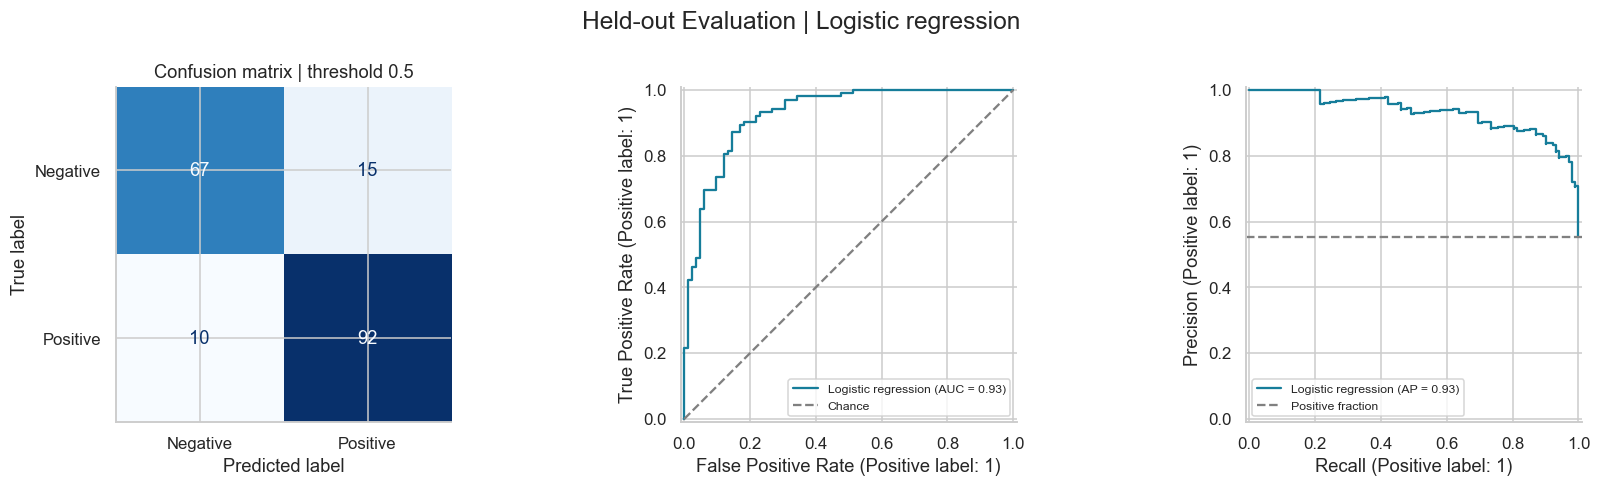

In [10]:
probability = selected.predict_proba(X_test)[:, 1]
prediction = selected.predict(X_test)
assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
test_metrics = pd.Series({
    'roc_auc': roc_auc_score(y_test, probability),
    'average_precision': average_precision_score(y_test, probability),
    'accuracy': accuracy_score(y_test, prediction),
    'balanced_accuracy': balanced_accuracy_score(y_test, prediction),
    'precision': precision_score(y_test, prediction, zero_division=0),
    'recall': recall_score(y_test, prediction, zero_division=0),
    'specificity': tn / (tn + fp),
    'f1': f1_score(y_test, prediction, zero_division=0),
    'brier_score': brier_score_loss(y_test, probability),
}, name=selected_name)
assert np.isfinite(test_metrics).all()
test_metrics.to_csv(REPORTS / 'test_metrics.csv', index_label='metric')
display(test_metrics.round(3).to_frame('holdout'))
print(classification_report(y_test, prediction, target_names=['Negative', 'Positive'], digits=3, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=['Negative', 'Positive'], cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title('Confusion matrix | threshold 0.5')
RocCurveDisplay.from_predictions(y_test, probability, name=selected_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Chance')
axes[1].legend(loc='lower right', fontsize=8)
PrecisionRecallDisplay.from_predictions(y_test, probability, name=selected_name, ax=axes[2])
axes[2].axhline(y_test.mean(), linestyle='--', color='gray', label='Positive fraction')
axes[2].legend(fontsize=8)
fig.suptitle('Held-out Evaluation | ' + selected_name, fontsize=16)
fig.tight_layout()
fig.savefig(REPORTS / 'evaluation.png', bbox_inches='tight')
plt.show()

### Uncertainty and subgroup diagnostics
A stratified bootstrap resamples holdout positives and negatives separately (1,000 repetitions), conditional on this fitted model
and observed class counts. The percentile interval captures sampling uncertainty in this test partition;
it excludes model-selection, training-sample, and external-population uncertainty.

Subgroup results are descriptive, with counts shown. Small denominators make rates unstable;
these tables do not establish fairness. Do not retune this model based on these holdout diagnostics.

In [11]:
rng = np.random.default_rng(SEED)
truth = y_test.to_numpy()
negative_indices = np.flatnonzero(truth == 0)
positive_indices = np.flatnonzero(truth == 1)
bootstrap_auc = []
for _ in range(1000):
    indices = np.concatenate([rng.choice(negative_indices, len(negative_indices), replace=True),
                              rng.choice(positive_indices, len(positive_indices), replace=True)])
    bootstrap_auc.append(roc_auc_score(truth[indices], probability[indices]))
auc_low, auc_high = np.quantile(bootstrap_auc, [0.025, 0.975])
print(f'Holdout ROC-AUC: {test_metrics.roc_auc:.3f} | stratified bootstrap 95% interval: [{auc_low:.3f}, {auc_high:.3f}]')

audit = data.loc[X_test.index, ['sex', 'dataset', 'target']].copy()
audit['prediction'] = prediction
subgroup_rows = []
for field in ['sex', 'dataset']:
    for group, frame in audit.groupby(field):
        negatives, positives = (frame.target == 0).sum(), (frame.target == 1).sum()
        subgroup_rows.append({'field': field, 'group': group, 'records': len(frame), 'positives': positives,
            'accuracy': accuracy_score(frame.target, frame.prediction),
            'recall': ((frame.target == 1) & (frame.prediction == 1)).sum() / positives if positives else np.nan,
            'specificity': ((frame.target == 0) & (frame.prediction == 0)).sum() / negatives if negatives else np.nan})
subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(REPORTS / 'subgroups.csv', index=False)
display(subgroups.round(3))

Holdout ROC-AUC: 0.926 | stratified bootstrap 95% interval: [0.888, 0.959]


,field,group,records,positives,accuracy,recall,specificity
0,sex,Female,35,8,0.943,0.875,0.963
1,sex,Male,149,94,0.846,0.904,0.745
2,dataset,Cleveland,55,26,0.836,0.923,0.759
3,dataset,Hungary,64,22,0.844,0.773,0.881
4,dataset,Switzerland,27,27,1.000,1.000,NaN
5,dataset,VA Long Beach,38,27,0.842,0.889,0.727


## 8. What does the model use?
Permutation importance measures the drop in ROC-AUC after shuffling one original input column on the holdout.
This is a post-evaluation diagnostic, not feature selection. Correlated inputs can share importance,
and small or negative values do not prove that a feature is irrelevant.

Logistic coefficients below come from a separate, predefined training-only logistic model.
They describe conditional associations in the transformed feature space, not causal effects or individual medical explanations.

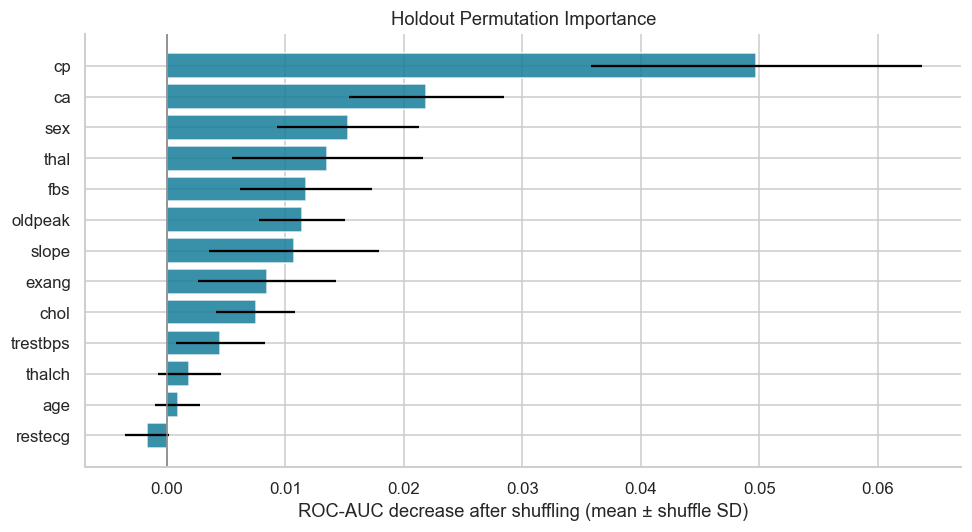

,coefficient
categorical__cp_atypical angina,-0.833403
categorical__sex_Female,-0.581974
categorical__thal_Missing,-0.557657
categorical__fbs_False,-0.461482
categorical__exang_False,-0.419071
categorical__slope_Missing,-0.355518
categorical__cp_asymptomatic,1.049737
categorical__slope_flat,0.765283
categorical__fbs_Missing,0.740710
numeric__missingindicator_ca,0.685660


In [12]:
importance = permutation_importance(selected, X_test, y_test, scoring='roc_auc', n_repeats=20, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'feature': FEATURES, 'mean_auc_drop': importance.importances_mean,
                                 'std_auc_drop': importance.importances_std}).sort_values('mean_auc_drop')
importance_table.to_csv(REPORTS / 'permutation_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance_table.feature, importance_table.mean_auc_drop, xerr=importance_table.std_auc_drop, color='#167d9a', alpha=0.85)
ax.axvline(0, color='gray', linewidth=1)
ax.set(xlabel='ROC-AUC decrease after shuffling (mean ± shuffle SD)', title='Holdout Permutation Importance')
fig.tight_layout()
fig.savefig(REPORTS / 'feature_importance.png', bbox_inches='tight')
plt.show()

logistic = clone(pipelines['Logistic regression']).fit(X_train, y_train)
coefficients = pd.Series(logistic.named_steps['model'].coef_[0],
                         index=logistic.named_steps['preprocess'].get_feature_names_out(), name='coefficient')
display(pd.concat([coefficients.nsmallest(6), coefficients.nlargest(6)]).to_frame())

## 9. PCA as an exploratory view
Fit imputation, scaling, and PCA on training numeric measurements only, excluding labels and identifiers.
PCA maximises feature variance, not disease discrimination. A two-dimensional overlap is not a model-quality test.
This numeric-only projection is a visual summary and is not an input to the classifiers.

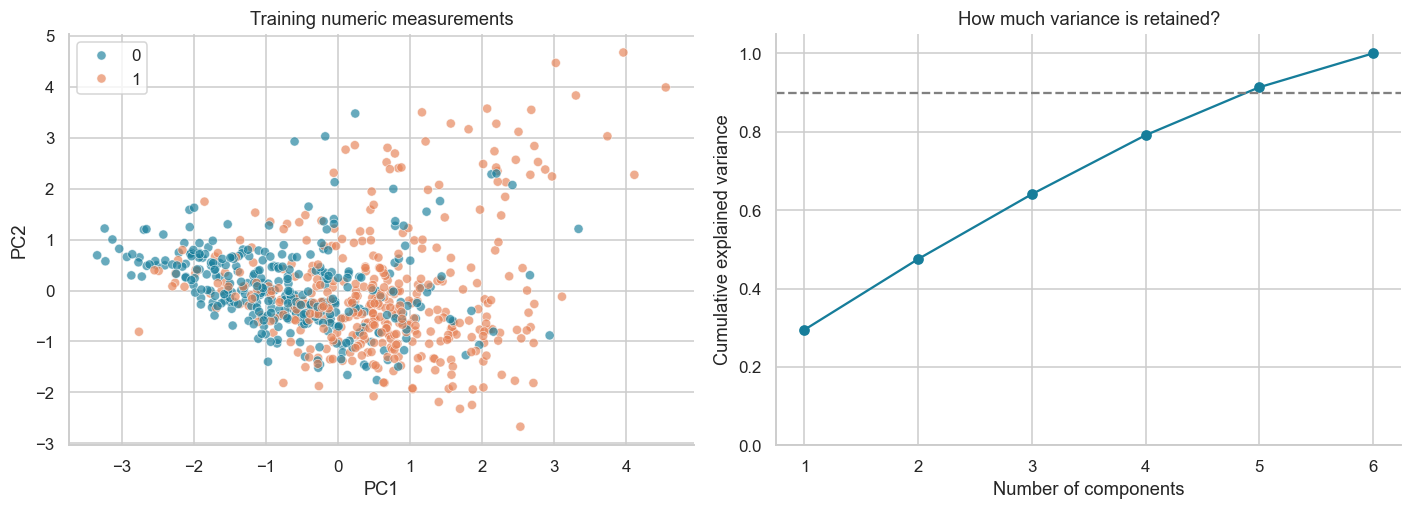

,PC1 loading,PC2 loading
age,0.578,-0.132
trestbps,0.389,-0.143
chol,0.156,0.203
thalch,-0.413,0.576
oldpeak,0.474,0.239
ca,0.309,0.730


In [13]:
pca_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('scale', StandardScaler()), ('pca', PCA()),
])
projection = pca_pipeline.fit_transform(X_train[NUMERIC])
pca = pca_pipeline.named_steps['pca']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(x=projection[:, 0], y=projection[:, 1], hue=y_train.to_numpy(), alpha=0.65, ax=axes[0])
axes[0].set(xlabel='PC1', ylabel='PC2', title='Training numeric measurements')
axes[1].plot(np.arange(1, len(NUMERIC) + 1), np.cumsum(pca.explained_variance_ratio_), marker='o', color='#167d9a')
axes[1].axhline(0.90, linestyle='--', color='gray')
axes[1].set(xlabel='Number of components', ylabel='Cumulative explained variance', ylim=(0, 1.05), title='How much variance is retained?')
fig.tight_layout()
plt.show()
display(pd.DataFrame(pca.components_[:2].T, index=NUMERIC, columns=['PC1 loading', 'PC2 loading']).round(3))

## 10. Conclusions and limitations
The run summary below is generated from computed results, so the reported numbers remain tied to this execution.
The practical lesson is to audit the sample and evaluation design before interpreting a high score.

- This is retrospective label classification, not prospective risk estimation. Several inputs require diagnostic procedures.
- Samples and missingness differ by hospital. A random holdout measures performance within this pooled sample;
  leave-one-site-out validation is a harder but still small, historical stress test.
- The sample is imbalanced by sex and not population-representative. Subgroup counts limit conclusions.
- Explicit zero-value corrections and conservative repeated-profile removal are documented assumptions.
  Sparse features and missingness indicators can encode recording practices.
- The model is not externally validated or clinically calibrated. No treatment or diagnosis decisions should rely on it.
- Future work should use independent contemporary data, a prespecified clinical use case, calibration assessment,
  and threshold selection using training/validation data only. Reusing this holdout to tune would invalidate its role.

In [14]:
print(f'Selected: {selected_name}')
print(f'Training CV ROC-AUC: {cv_results.loc[selected_name, "roc_auc_mean"]:.3f} ± {cv_results.loc[selected_name, "roc_auc_std"]:.3f} (fold SD)')
print(f'Holdout: {len(y_test)} records | ROC-AUC {test_metrics.roc_auc:.3f} | Recall {test_metrics.recall:.3f} | Specificity {test_metrics.specificity:.3f}')
print(f'At threshold 0.5: {fn} false negatives and {fp} false positives.')
print(f'Site-transfer ROC-AUC range: {site_results.roc_auc.min():.3f}–{site_results.roc_auc.max():.3f}')
print('All outputs were generated locally; see reports/ for figures and metric tables.')

Selected: Logistic regression
Training CV ROC-AUC: 0.888 ± 0.053 (fold SD)
Holdout: 184 records | ROC-AUC 0.926 | Recall 0.902 | Specificity 0.817
At threshold 0.5: 10 false negatives and 15 false positives.
Site-transfer ROC-AUC range: 0.684–0.903
All outputs were generated locally; see reports/ for figures and metric tables.
